In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import combinations
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
elif not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "events.csv"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

events = pd.read_csv(DATA_PATH)

events["timestamp"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

print("Dataset shape:", events.shape)
print("Unique users:", events["visitorid"].nunique())
print("Unique items:", events["itemid"].nunique())
print("Event types:")
display(events["event"].value_counts())

Dataset shape: (2756101, 5)
Unique users: 1407580
Unique items: 235061
Event types:


event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64

In [4]:
transactions = events.loc[
    events["event"] == "transaction"
].copy()

print("Transaction events:", len(transactions))
print("Unique transaction users:", transactions["visitorid"].nunique())
print("Unique transaction items:", transactions["itemid"].nunique())

print(
    "Users with multiple transaction events:",
    (transactions.groupby("visitorid").size() > 1).sum()
)

print(
    "Users with multiple transaction items:",
    transactions.groupby("visitorid")["itemid"].nunique().gt(1).sum()
)

display(transactions.head())

Transaction events: 22457
Unique transaction users: 11719
Unique transaction items: 12025
Users with multiple transaction events: 2576
Users with multiple transaction items: 2174


,timestamp,visitorid,event,itemid,transactionid
130,2015-06-02 05:17:56.276+00:00,599528,transaction,356475,"4,000.0000"
304,2015-06-01 21:18:20.981+00:00,121688,transaction,15335,"11,117.0000"
418,2015-06-01 21:25:15.008+00:00,552148,transaction,81345,"5,444.0000"
814,2015-06-01 16:38:56.375+00:00,102019,transaction,150318,"13,556.0000"
843,2015-06-01 16:01:58.180+00:00,189384,transaction,310791,"7,244.0000"


In [5]:
transaction_structure = {
    "transaction_events": len(transactions),
    "unique_users": transactions["visitorid"].nunique(),
    "unique_items": transactions["itemid"].nunique(),
    "unique_user_item_pairs": transactions[
        ["visitorid", "itemid"]
    ].drop_duplicates().shape[0],
    "users_with_multiple_transaction_events": (
        transactions.groupby("visitorid").size().gt(1).sum()
    ),
    "items_with_multiple_buyers": (
        transactions.groupby("itemid")["visitorid"].nunique().gt(1).sum()
    )
}

transaction_structure = pd.Series(transaction_structure)

display(transaction_structure.to_frame("value"))

transaction_structure.to_csv(
    TABLES_DIR / "07_transaction_structure.csv"
)

,value
transaction_events,22457
unique_users,11719
unique_items,12025
unique_user_item_pairs,21270
users_with_multiple_transaction_events,2576
items_with_multiple_buyers,3969


In [6]:
print("Unique transaction IDs:", transactions["transactionid"].nunique())

print(
    "Missing transaction IDs:",
    transactions["transactionid"].isna().sum()
)

print(
    "Duplicate transaction records:",
    transactions.duplicated().sum()
)

print(
    "Transactions with multiple items:",
    (
        transactions.groupby("transactionid")["itemid"]
        .nunique()
        .gt(1)
        .sum()
    )
)

Unique transaction IDs: 17672
Missing transaction IDs: 0
Duplicate transaction records: 0
Transactions with multiple items: 2643


In [7]:
transaction_users = (
    transactions.groupby("transactionid")["visitorid"]
    .nunique()
)

print("Transactions linked to multiple users:", (transaction_users > 1).sum())
print("Transactions linked to one user:", (transaction_users == 1).sum())

display(
    transaction_users.value_counts()
    .sort_index()
    .to_frame("transaction_count")
)

Transactions linked to multiple users: 0
Transactions linked to one user: 17672


,transaction_count
visitorid,
1,17672


In [8]:
orders = (
    transactions
    .groupby(["transactionid", "visitorid"])
    .agg(
        order_timestamp=("timestamp", "min"),
        items_count=("itemid", "nunique"),
        event_rows=("itemid", "size")
    )
    .reset_index()
)

print("Orders:", orders["transactionid"].nunique())
print("Users:", orders["visitorid"].nunique())

display(orders.head())

print("\nItems per order:")
display(orders["items_count"].describe())

print("\nOrder records per user:")
display(orders.groupby("visitorid").size().describe())

Orders: 17672
Users: 11719


,transactionid,visitorid,order_timestamp,items_count,event_rows
0,0.0000,90352,2015-06-15 21:36:37.081+00:00,1,1
1,1.0000,1150086,2015-07-14 18:30:08.851+00:00,1,1
2,2.0000,556967,2015-06-03 18:02:29.857+00:00,1,1
3,3.0000,424452,2015-06-22 00:12:41.626+00:00,1,1
4,4.0000,531661,2015-06-07 22:40:24.966+00:00,1,1



Items per order:


count   17,672.0000
mean         1.2632
std          0.9407
min          1.0000
25%          1.0000
50%          1.0000
75%          1.0000
max         31.0000
Name: items_count, dtype: float64


Order records per user:


count   11,719.0000
mean         1.5080
std          7.3445
min          1.0000
25%          1.0000
50%          1.0000
75%          1.0000
max        502.0000
dtype: float64

In [9]:
order_id_users = orders.groupby("transactionid")["visitorid"].nunique()

assert order_id_users.max() == 1, (
    "Some transaction IDs are linked to multiple users"
)

assert orders["transactionid"].is_unique, (
    "Order table contains duplicate transaction IDs"
)

print("Order table validation passed.")

Order table validation passed.


In [11]:
orders_per_user = (
    orders.groupby("visitorid")["transactionid"]
    .nunique()
    .rename("orders_count")
)

repeat_purchase_summary = pd.Series({
    "total_buyers": len(orders_per_user),
    "one_order_buyers": (orders_per_user == 1).sum(),
    "repeat_buyers": (orders_per_user > 1).sum(),
    "repeat_buyer_share": (orders_per_user > 1).mean(),
    "average_orders_per_buyer": orders_per_user.mean(),
    "median_orders_per_buyer": orders_per_user.median(),
    "maximum_orders_per_buyer": orders_per_user.max()
})

display(repeat_purchase_summary.to_frame("value"))

,value
total_buyers,"11,719.0000"
one_order_buyers,"10,656.0000"
repeat_buyers,"1,063.0000"
repeat_buyer_share,0.0907
average_orders_per_buyer,1.5080
median_orders_per_buyer,1.0000
maximum_orders_per_buyer,502.0000


In [12]:
orders_distribution = (
    orders_per_user
    .value_counts()
    .sort_index()
    .rename_axis("orders_count")
    .reset_index(name="buyers")
)

orders_distribution["buyer_share"] = (
    orders_distribution["buyers"] / len(orders_per_user)
)

display(orders_distribution.head(20))

orders_distribution.to_csv(
    TABLES_DIR / "07_orders_per_user_distribution.csv",
    index=False
)

,orders_count,buyers,buyer_share
0,1,10656,0.9093
1,2,748,0.0638
2,3,133,0.0113
3,4,44,0.0038
4,5,13,0.0011
5,6,13,0.0011
6,7,9,0.0008
7,8,6,0.0005
8,9,7,0.0006
9,10,6,0.0005


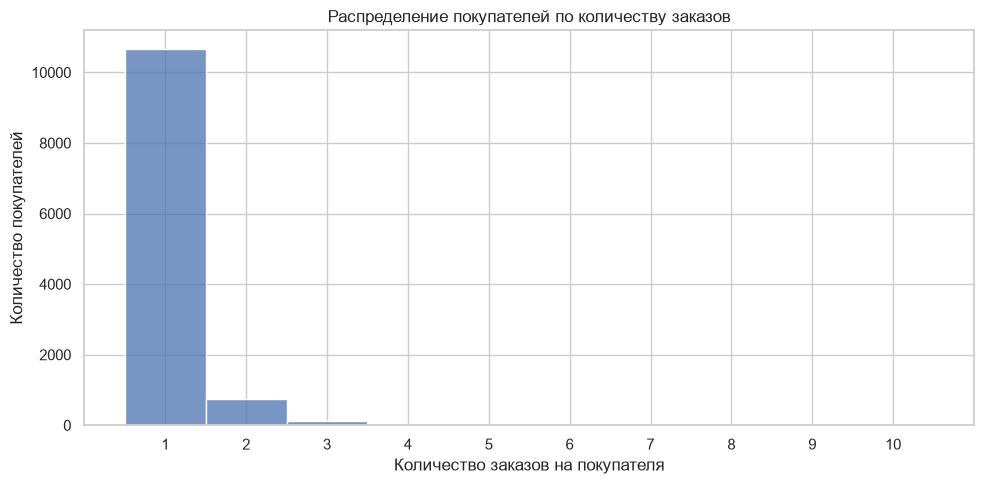

In [13]:
plot_data = orders_per_user[
    orders_per_user <= 10
]

fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    plot_data,
    bins=np.arange(0.5, 11.5, 1),
    ax=ax
)

ax.set_title("Распределение покупателей по количеству заказов")
ax.set_xlabel("Количество заказов на покупателя")
ax.set_ylabel("Количество покупателей")
ax.set_xticks(range(1, 11))

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "07_orders_per_user_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [14]:
buyer_order_summary = (
    orders_per_user
    .gt(1)
    .groupby(orders_per_user.gt(1))
    .size()
)

orders_by_buyer_type = (
    orders.assign(
        buyer_type=orders["visitorid"].map(
            lambda x: "Repeat buyer"
            if orders_per_user.loc[x] > 1
            else "One-time buyer"
        )
    )
    .groupby("buyer_type")
    .agg(
        buyers=("visitorid", "nunique"),
        orders=("transactionid", "nunique")
    )
)

orders_by_buyer_type["buyer_share"] = (
    orders_by_buyer_type["buyers"] / orders_per_user.size
)

orders_by_buyer_type["order_share"] = (
    orders_by_buyer_type["orders"] / len(orders)
)

display(orders_by_buyer_type)

orders_by_buyer_type.to_csv(
    TABLES_DIR / "07_orders_by_buyer_type.csv"
)

,buyers,orders,buyer_share,order_share
buyer_type,,,,
One-time buyer,10656,10656,0.9093,0.6030
Repeat buyer,1063,7016,0.0907,0.3970


In [15]:
orders_sorted = orders.sort_values(
    ["visitorid", "order_timestamp"]
).copy()

orders_sorted["previous_order_timestamp"] = (
    orders_sorted.groupby("visitorid")["order_timestamp"].shift(1)
)

orders_sorted["days_between_orders"] = (
    orders_sorted["order_timestamp"]
    - orders_sorted["previous_order_timestamp"]
).dt.total_seconds() / 86400

interpurchase_time = orders_sorted["days_between_orders"].dropna()

print("Repeat purchase intervals:", len(interpurchase_time))
display(interpurchase_time.describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
))

Repeat purchase intervals: 5953


count   5,953.0000
mean        2.1078
std         8.5656
min         0.0006
25%         0.0133
50%         0.0369
75%         0.1778
90%         3.2553
95%        10.9941
99%        47.5522
max       112.4770
Name: days_between_orders, dtype: float64

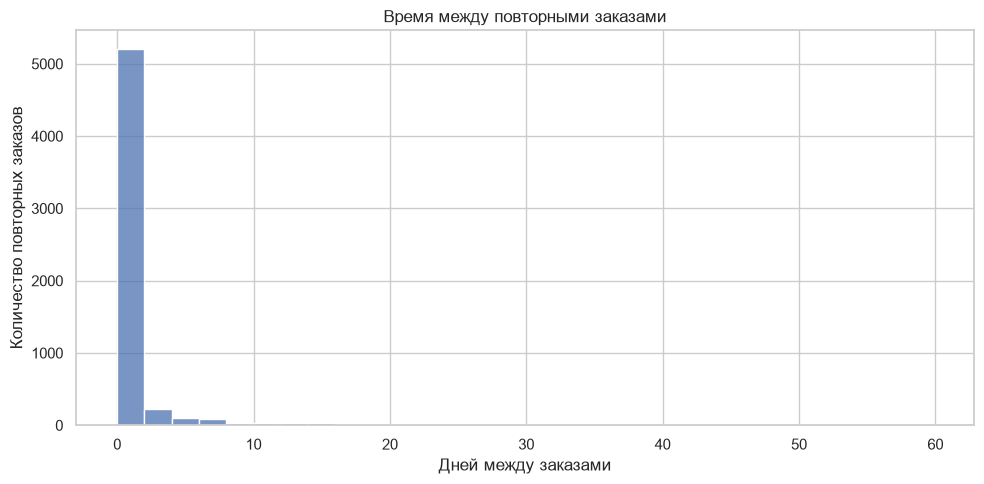

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    interpurchase_time[interpurchase_time <= 60],
    bins=30,
    ax=ax
)

ax.set_title("Время между повторными заказами")
ax.set_xlabel("Дней между заказами")
ax.set_ylabel("Количество повторных заказов")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "07_interpurchase_time.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [17]:
top_repeat_buyers = (
    orders_per_user
    .sort_values(ascending=False)
    .head(10)
    .rename("orders_count")
    .reset_index()
)

display(top_repeat_buyers)

top_buyer_ids = top_repeat_buyers["visitorid"]

top_buyer_timeline = (
    orders[orders["visitorid"].isin(top_buyer_ids)]
    .sort_values(["visitorid", "order_timestamp"])
)

display(
    top_buyer_timeline.groupby("visitorid").agg(
        orders=("transactionid", "nunique"),
        first_order=("order_timestamp", "min"),
        last_order=("order_timestamp", "max"),
        unique_items=("items_count", "sum")
    ).sort_values("orders", ascending=False)
)

,visitorid,orders_count
0,1150086,502
1,152963,278
2,530559,221
3,684514,162
4,76757,155
5,861299,148
6,138131,137
7,247235,124
8,1297062,111
9,890980,104


,orders,first_order,last_order,unique_items
visitorid,,,,
1150086,502,2015-06-11 15:28:45.614+00:00,2015-09-17 00:24:58.943+00:00,559
152963,278,2015-08-03 17:16:29.561+00:00,2015-09-18 02:43:12.017+00:00,349
530559,221,2015-06-15 19:36:51.103+00:00,2015-09-12 23:16:45.863+00:00,284
684514,162,2015-06-17 16:47:14.489+00:00,2015-07-06 20:00:53.922+00:00,189
76757,155,2015-05-06 17:53:17.506+00:00,2015-06-24 00:34:21.485+00:00,185
861299,148,2015-07-24 16:40:58.756+00:00,2015-08-19 02:23:13.196+00:00,188
138131,137,2015-05-04 15:59:58.661+00:00,2015-07-02 15:55:18.473+00:00,173
247235,124,2015-08-13 22:28:15.027+00:00,2015-09-14 22:58:30.256+00:00,132
1297062,111,2015-07-03 18:06:20.969+00:00,2015-08-03 23:27:48.159+00:00,136


In [18]:
top_buyer_item_counts = (
    transactions[
        transactions["visitorid"].isin(top_buyer_ids)
    ]
    .groupby("visitorid")["itemid"]
    .nunique()
    .rename("unique_items")
)

display(top_buyer_item_counts.sort_values(ascending=False))

visitorid
1150086    532
152963     319
530559     259
684514     184
861299     183
76757      177
138131     161
247235     129
1297062    129
890980     126
Name: unique_items, dtype: int64

In [20]:
observation_end = events["timestamp"].max()

rfm = (
    orders.groupby("visitorid")
    .agg(
        last_order=("order_timestamp", "max"),
        frequency=("transactionid", "nunique")
    )
    .reset_index()
)

rfm["recency"] = (
    observation_end - rfm["last_order"]
).dt.total_seconds() / 86400

product_breadth = (
    transactions.groupby("visitorid")["itemid"]
    .nunique()
    .rename("unique_items")
)

rfm = rfm.merge(
    product_breadth,
    on="visitorid",
    how="left"
)

print("Observation end:", observation_end)
print("RFM customers:", len(rfm))

display(rfm.head())
display(
    rfm[["recency", "frequency", "unique_items"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
)

Observation end: 2015-09-18 02:59:47.788000+00:00
RFM customers: 11719


,visitorid,last_order,frequency,recency,unique_items
0,172,2015-08-15 01:29:01.230+00:00,1,34.0630,2
1,186,2015-08-12 16:34:57.040+00:00,1,36.4339,1
2,264,2015-09-07 17:34:45.614+00:00,1,10.3924,2
3,419,2015-07-29 05:03:12.695+00:00,1,50.9143,1
4,539,2015-06-16 05:39:38.673+00:00,1,93.8890,1


,recency,frequency,unique_items
count,"11,719.0000","11,719.0000","11,719.0000"
mean,70.2649,1.5080,1.8150
std,39.0897,7.3445,8.3473
min,0.0115,1.0000,1.0000
25%,37.2558,1.0000,1.0000
50%,70.8973,1.0000,1.0000
75%,104.2297,1.0000,1.0000
90%,124.3429,1.0000,2.0000
95%,131.9292,2.0000,3.0000
99%,136.2227,6.0000,11.0000


In [27]:
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

frequency_bins = [0, 1, 2, 3, 5, np.inf]
frequency_labels = [1, 2, 3, 4, 5]

rfm["F_score"] = pd.cut(
    rfm["frequency"],
    bins=frequency_bins,
    labels=frequency_labels
).astype(int)

rfm["RF_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
)

display(
    rfm[
        ["visitorid", "recency", "frequency",
         "R_score", "F_score", "RF_score"]
    ].head(10)
)

print("\nFrequency score distribution:")
display(rfm["F_score"].value_counts().sort_index())

,visitorid,recency,frequency,R_score,F_score,RF_score
0,172,34.0630,1,4,1,41
1,186,36.4339,1,4,1,41
2,264,10.3924,1,5,1,51
3,419,50.9143,1,4,1,41
4,539,93.8890,1,2,1,21
5,627,28.2578,1,5,1,51
6,795,38.2067,1,4,1,41
7,914,31.0896,1,4,1,41
8,964,65.3023,1,3,1,31
9,1032,83.3132,1,3,1,31



Frequency score distribution:


F_score
1    10656
2      748
3      133
4       57
5      125
Name: count, dtype: int64

In [28]:
def assign_rf_segment(row):
    r = row["R_score"]
    f = row["F_score"]

    if r >= 4 and f >= 4:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal Customers"
    elif r >= 4 and f <= 2:
        return "Recent Customers"
    elif r <= 2 and f >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2:
        return "Hibernating"
    else:
        return "Potential Loyalists"


rfm["segment"] = rfm.apply(assign_rf_segment, axis=1)

segment_summary = (
    rfm.groupby("segment")
    .agg(
        customers=("visitorid", "nunique"),
        avg_recency=("recency", "mean"),
        median_recency=("recency", "median"),
        avg_frequency=("frequency", "mean"),
        median_frequency=("frequency", "median"),
        avg_unique_items=("unique_items", "mean")
    )
    .sort_values("customers", ascending=False)
)

segment_summary["customer_share"] = (
    segment_summary["customers"] / len(rfm)
)

display(segment_summary)

,customers,avg_recency,median_recency,avg_frequency,median_frequency,avg_unique_items,customer_share
segment,,,,,,,
Hibernating,4580,110.6104,110.8336,1.0653,1.0000,1.2642,0.3908
Recent Customers,4541,30.0213,29.9716,1.0665,1.0000,1.3319,0.3875
Potential Loyalists,2374,69.3530,70.3841,1.1386,1.0000,1.3694,0.2026
At Risk,108,108.7876,107.8896,14.5926,4.0000,17.3148,0.0092
Champions,85,23.5153,22.3846,33.9294,9.0000,39.5176,0.0073
Loyal Customers,31,68.3755,66.4998,25.3871,11.0000,30.7097,0.0026


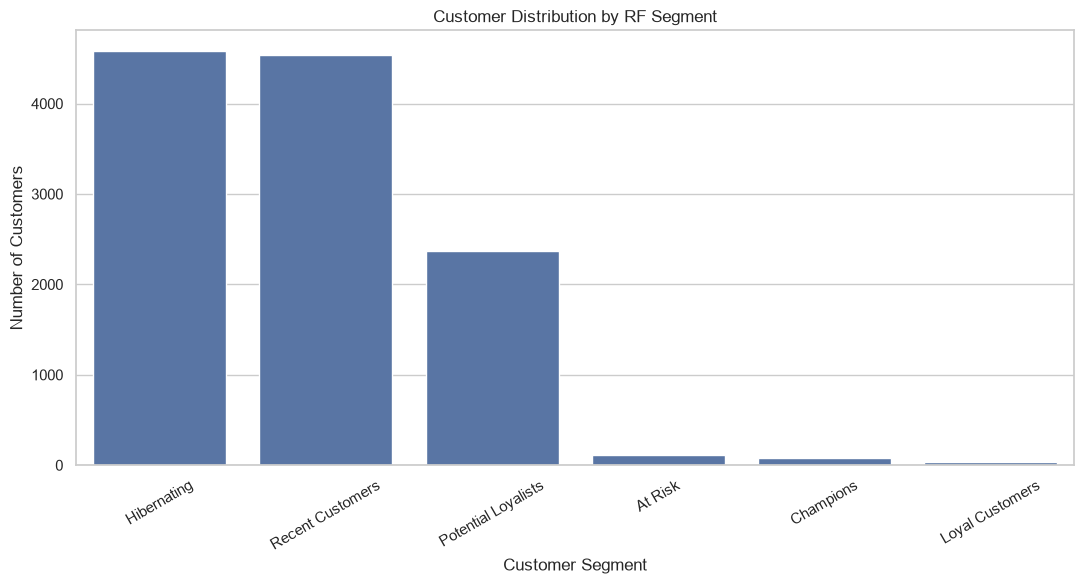

In [29]:
fig, ax = plt.subplots(figsize=(11, 6))

segment_counts = rfm["segment"].value_counts()

sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    ax=ax
)

ax.set_title("Customer Distribution by RF Segment")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Number of Customers")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "07_rf_customer_segments.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

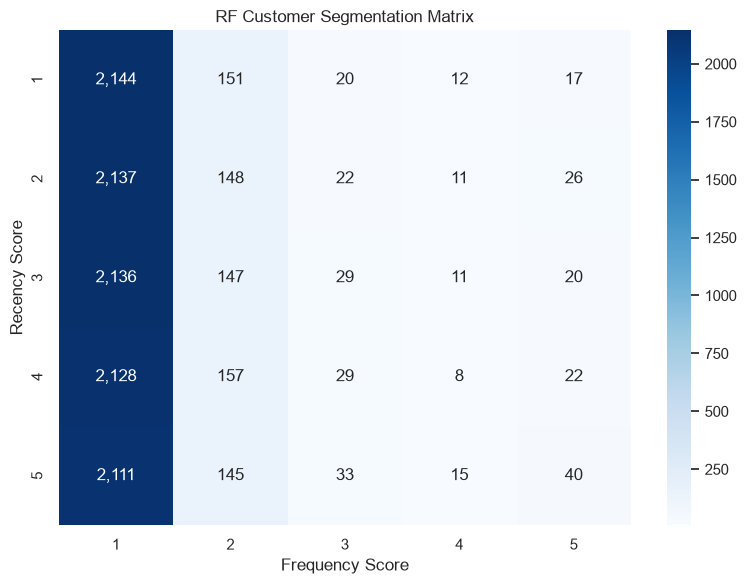

In [30]:
rf_matrix = pd.pivot_table(
    rfm,
    values="visitorid",
    index="R_score",
    columns="F_score",
    aggfunc="count",
    fill_value=0
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    rf_matrix,
    annot=True,
    fmt=",",
    cmap="Blues",
    ax=ax
)

ax.set_title("RF Customer Segmentation Matrix")
ax.set_xlabel("Frequency Score")
ax.set_ylabel("Recency Score")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "07_rf_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [31]:
rfm.to_csv(
    TABLES_DIR / "07_customer_rf_segments.csv",
    index=False
)

segment_summary.to_csv(
    TABLES_DIR / "07_rf_segment_summary.csv"
)

print("RF analysis tables saved.")

RF analysis tables saved.


In [32]:
print("Total customers:", len(rfm))
print("Segment customers:", segment_summary["customers"].sum())
print("Total segment share:", segment_summary["customer_share"].sum())

assert segment_summary["customers"].sum() == len(rfm)
assert np.isclose(segment_summary["customer_share"].sum(), 1)

Total customers: 11719
Segment customers: 11719
Total segment share: 1.0


In [33]:
frequency_score_check = (
    rfm.groupby("frequency")["F_score"]
    .nunique()
)

print(
    "Frequency values with multiple scores:",
    (frequency_score_check > 1).sum()
)

assert (frequency_score_check <= 1).all()

Frequency values with multiple scores: 0


In [34]:
basket_items = (
    transactions[["transactionid", "itemid"]]
    .drop_duplicates()
)

baskets = (
    basket_items.groupby("transactionid")["itemid"]
    .apply(lambda x: sorted(x.tolist()))
)

basket_sizes = baskets.str.len()

print("Total orders:", len(baskets))
print("Single-item orders:", (basket_sizes == 1).sum())
print("Multi-item orders:", (basket_sizes > 1).sum())
print("Share of multi-item orders:", (basket_sizes > 1).mean())

print("\nBasket size distribution:")
display(basket_sizes.describe())

Total orders: 17672
Single-item orders: 15029
Multi-item orders: 2643
Share of multi-item orders: 0.1495586238116795

Basket size distribution:


count   17,672.0000
mean         1.2632
std          0.9407
min          1.0000
25%          1.0000
50%          1.0000
75%          1.0000
max         31.0000
Name: itemid, dtype: float64

In [35]:
item_order_frequency = (
    basket_items.groupby("itemid")["transactionid"]
    .nunique()
    .sort_values(ascending=False)
    .rename("order_count")
    .reset_index()
)

display(item_order_frequency.head(20))

item_order_frequency.to_csv(
    TABLES_DIR / "07_item_order_frequency.csv",
    index=False
)

,itemid,order_count
0,461686,133
1,119736,96
2,213834,92
3,7943,46
4,312728,46
5,445351,45
6,48030,41
7,248455,38
8,420960,38
9,17478,37


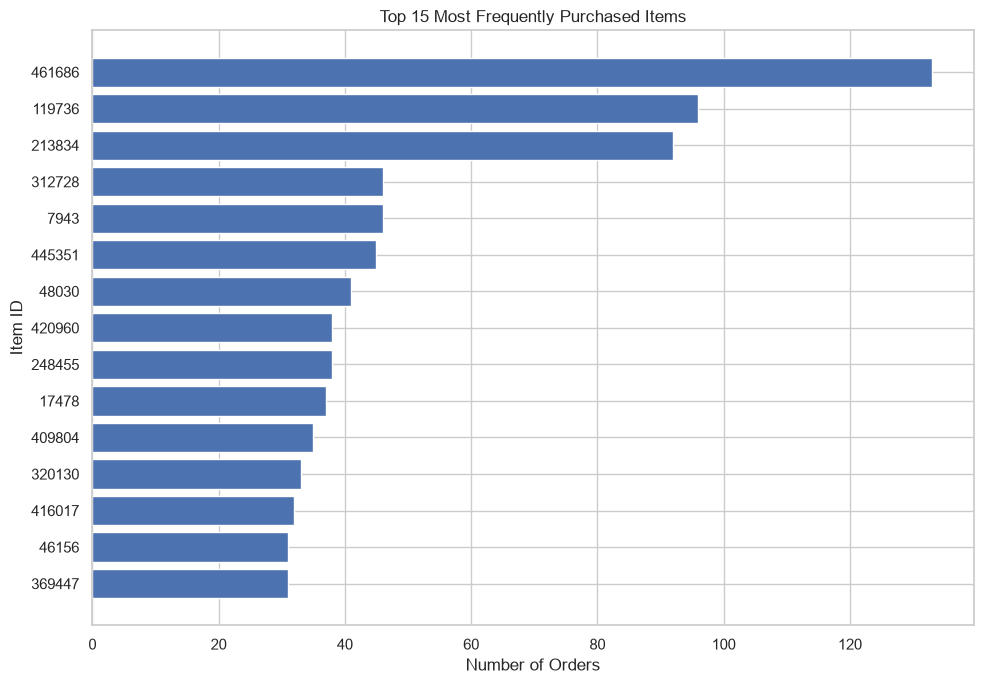

In [36]:
top_items = item_order_frequency.head(15).sort_values(
    "order_count",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    top_items["itemid"].astype(str),
    top_items["order_count"]
)

ax.set_title("Top 15 Most Frequently Purchased Items")
ax.set_xlabel("Number of Orders")
ax.set_ylabel("Item ID")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "07_top_purchased_items.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [37]:
from collections import Counter

pair_counter = Counter()

for items in baskets:
    if len(items) < 2:
        continue

    for item_a, item_b in combinations(items, 2):
        pair_counter[(item_a, item_b)] += 1

pair_counts = pd.DataFrame(
    [
        {
            "item_a": item_a,
            "item_b": item_b,
            "pair_orders": count
        }
        for (item_a, item_b), count in pair_counter.items()
    ]
)

pair_counts = pair_counts.sort_values(
    "pair_orders",
    ascending=False
).reset_index(drop=True)

print("Unique item pairs:", len(pair_counts))
display(pair_counts.head(20))

Unique item pairs: 9688


,item_a,item_b,pair_orders
0,213834,445351,39
1,171878,461686,9
2,10572,461686,8
3,32581,461686,8
4,218794,461686,8
5,301721,369158,7
6,78268,449391,6
7,10572,357529,5
8,28789,132633,5
9,46130,213834,5


In [38]:
total_orders = len(baskets)

item_order_counts = (
    basket_items.groupby("itemid")["transactionid"]
    .nunique()
)

pair_metrics = pair_counts.copy()

pair_metrics["support"] = (
    pair_metrics["pair_orders"] / total_orders
)

pair_metrics["confidence_a_to_b"] = (
    pair_metrics["pair_orders"]
    / pair_metrics["item_a"].map(item_order_counts)
)

pair_metrics["confidence_b_to_a"] = (
    pair_metrics["pair_orders"]
    / pair_metrics["item_b"].map(item_order_counts)
)

pair_metrics["support_a"] = (
    pair_metrics["item_a"].map(item_order_counts)
    / total_orders
)

pair_metrics["support_b"] = (
    pair_metrics["item_b"].map(item_order_counts)
    / total_orders
)

pair_metrics["lift"] = (
    pair_metrics["support"]
    / (pair_metrics["support_a"] * pair_metrics["support_b"])
)

pair_metrics = pair_metrics.sort_values(
    ["pair_orders", "lift"],
    ascending=False
)

display(pair_metrics.head(20))

,item_a,item_b,pair_orders,support,confidence_a_to_b,confidence_b_to_a,support_a,support_b,lift
0,213834,445351,39,0.0022,0.4239,0.8667,0.0052,0.0025,166.4754
1,171878,461686,9,0.0005,0.6923,0.0677,0.0007,0.0075,91.9884
3,32581,461686,8,0.0005,1.0000,0.0602,0.0005,0.0075,132.8722
4,218794,461686,8,0.0005,0.7273,0.0602,0.0006,0.0075,96.6343
2,10572,461686,8,0.0005,0.4211,0.0602,0.0011,0.0075,55.9462
5,301721,369158,7,0.0004,0.3889,0.3684,0.0010,0.0011,361.7076
6,78268,449391,6,0.0003,0.8571,0.5000,0.0004,0.0007,"1,262.2857"
8,28789,132633,5,0.0003,1.0000,0.7143,0.0003,0.0004,"2,524.5714"
11,379520,432171,5,0.0003,0.2941,1.0000,0.0010,0.0003,"1,039.5294"
7,10572,357529,5,0.0003,0.2632,1.0000,0.0011,0.0003,930.1053


In [39]:
MIN_PAIR_ORDERS = 5

reliable_pairs = pair_metrics[
    pair_metrics["pair_orders"] >= MIN_PAIR_ORDERS
].copy()

print("Pairs before filtering:", len(pair_metrics))
print("Pairs after filtering:", len(reliable_pairs))

print("\nTop pairs by frequency:")
display(
    reliable_pairs.sort_values(
        "pair_orders",
        ascending=False
    ).head(20)
)

print("\nTop pairs by lift:")
display(
    reliable_pairs.sort_values(
        "lift",
        ascending=False
    ).head(20)
)

Pairs before filtering: 9688
Pairs after filtering: 12

Top pairs by frequency:


,item_a,item_b,pair_orders,support,confidence_a_to_b,confidence_b_to_a,support_a,support_b,lift
0,213834,445351,39,0.0022,0.4239,0.8667,0.0052,0.0025,166.4754
1,171878,461686,9,0.0005,0.6923,0.0677,0.0007,0.0075,91.9884
3,32581,461686,8,0.0005,1.0000,0.0602,0.0005,0.0075,132.8722
4,218794,461686,8,0.0005,0.7273,0.0602,0.0006,0.0075,96.6343
2,10572,461686,8,0.0005,0.4211,0.0602,0.0011,0.0075,55.9462
5,301721,369158,7,0.0004,0.3889,0.3684,0.0010,0.0011,361.7076
6,78268,449391,6,0.0003,0.8571,0.5000,0.0004,0.0007,"1,262.2857"
8,28789,132633,5,0.0003,1.0000,0.7143,0.0003,0.0004,"2,524.5714"
11,379520,432171,5,0.0003,0.2941,1.0000,0.0010,0.0003,"1,039.5294"
7,10572,357529,5,0.0003,0.2632,1.0000,0.0011,0.0003,930.1053



Top pairs by lift:


,item_a,item_b,pair_orders,support,confidence_a_to_b,confidence_b_to_a,support_a,support_b,lift
8,28789,132633,5,0.0003,1.0000,0.7143,0.0003,0.0004,"2,524.5714"
6,78268,449391,6,0.0003,0.8571,0.5000,0.0004,0.0007,"1,262.2857"
11,379520,432171,5,0.0003,0.2941,1.0000,0.0010,0.0003,"1,039.5294"
7,10572,357529,5,0.0003,0.2632,1.0000,0.0011,0.0003,930.1053
10,256146,273872,5,0.0003,0.3846,0.5556,0.0007,0.0005,755.2137
5,301721,369158,7,0.0004,0.3889,0.3684,0.0010,0.0011,361.7076
0,213834,445351,39,0.0022,0.4239,0.8667,0.0052,0.0025,166.4754
9,46130,213834,5,0.0003,0.7143,0.0543,0.0004,0.0052,137.2050
3,32581,461686,8,0.0005,1.0000,0.0602,0.0005,0.0075,132.8722
4,218794,461686,8,0.0005,0.7273,0.0602,0.0006,0.0075,96.6343


In [ ]:
pair_metrics.to_csv(
    TABLES_DIR / "07_all_product_pairs.csv",
    index=False
)

reliable_pairs.to_csv(
    TABLES_DIR / "07_reliable_product_pairs.csv",
    index=False
)

print("Product co-occurrence tables saved.")

Product co-occurrence tables saved.


In [41]:
thresholds = [2, 3, 5, 10, 15, 20, 30]

threshold_sensitivity = pd.DataFrame({
    "min_pair_orders": thresholds,
    "remaining_pairs": [
        (pair_metrics["pair_orders"] >= threshold).sum()
        for threshold in thresholds
    ]
})

display(threshold_sensitivity)

threshold_sensitivity.to_csv(
    TABLES_DIR / "07_pair_threshold_sensitivity.csv",
    index=False
)

,min_pair_orders,remaining_pairs
0,2,903
1,3,79
2,5,12
3,10,1
4,15,1
5,20,1
6,30,1


In [42]:
MIN_RECOMMENDATION_ORDERS = 5

recommendation_candidates = pair_metrics[
    pair_metrics["pair_orders"] >= MIN_RECOMMENDATION_ORDERS
].copy()

recommendation_candidates["min_directional_confidence"] = (
    recommendation_candidates[
        ["confidence_a_to_b", "confidence_b_to_a"]
    ].min(axis=1)
)

recommendation_candidates = recommendation_candidates.sort_values(
    ["pair_orders", "lift"],
    ascending=False
)

display(
    recommendation_candidates[
        [
            "item_a",
            "item_b",
            "pair_orders",
            "support",
            "confidence_a_to_b",
            "confidence_b_to_a",
            "lift"
        ]
    ]
)

,item_a,item_b,pair_orders,support,confidence_a_to_b,confidence_b_to_a,lift
0,213834,445351,39,0.0022,0.4239,0.8667,166.4754
1,171878,461686,9,0.0005,0.6923,0.0677,91.9884
3,32581,461686,8,0.0005,1.0000,0.0602,132.8722
4,218794,461686,8,0.0005,0.7273,0.0602,96.6343
2,10572,461686,8,0.0005,0.4211,0.0602,55.9462
5,301721,369158,7,0.0004,0.3889,0.3684,361.7076
6,78268,449391,6,0.0003,0.8571,0.5000,"1,262.2857"
8,28789,132633,5,0.0003,1.0000,0.7143,"2,524.5714"
11,379520,432171,5,0.0003,0.2941,1.0000,"1,039.5294"
7,10572,357529,5,0.0003,0.2632,1.0000,930.1053


In [43]:
rules_a_to_b = recommendation_candidates[
    [
        "item_a",
        "item_b",
        "pair_orders",
        "confidence_a_to_b",
        "lift"
    ]
].rename(columns={
    "item_a": "antecedent",
    "item_b": "recommended_item",
    "confidence_a_to_b": "confidence"
})

rules_b_to_a = recommendation_candidates[
    [
        "item_b",
        "item_a",
        "pair_orders",
        "confidence_b_to_a",
        "lift"
    ]
].rename(columns={
    "item_b": "antecedent",
    "item_a": "recommended_item",
    "confidence_b_to_a": "confidence"
})

recommendation_rules = pd.concat(
    [rules_a_to_b, rules_b_to_a],
    ignore_index=True
)

recommendation_rules = recommendation_rules.sort_values(
    ["antecedent", "confidence", "pair_orders"],
    ascending=[True, False, False]
).reset_index(drop=True)

display(recommendation_rules.head(20))

,antecedent,recommended_item,pair_orders,confidence,lift
0,10572,461686,8,0.4211,55.9462
1,10572,357529,5,0.2632,930.1053
2,28789,132633,5,1.0000,"2,524.5714"
3,32581,461686,8,1.0000,132.8722
4,46130,213834,5,0.7143,137.2050
5,78268,449391,6,0.8571,"1,262.2857"
6,132633,28789,5,0.7143,"2,524.5714"
7,171878,461686,9,0.6923,91.9884
8,213834,445351,39,0.4239,166.4754
9,213834,46130,5,0.0543,137.2050


In [44]:
def recommend_products(item_id, top_n=5):
    recommendations = (
        recommendation_rules[
            recommendation_rules["antecedent"] == item_id
        ]
        .sort_values(
            ["confidence", "pair_orders"],
            ascending=False
        )
        .head(top_n)
    )

    if recommendations.empty:
        return pd.DataFrame(
            columns=[
                "antecedent",
                "recommended_item",
                "pair_orders",
                "confidence",
                "lift"
            ]
        )

    return recommendations[
        [
            "antecedent",
            "recommended_item",
            "pair_orders",
            "confidence",
            "lift"
        ]
    ]

In [45]:
test_items = [213834, 445351, 461686, 28789]

for item_id in test_items:
    print(f"\nRecommendations for item {item_id}:")
    display(recommend_products(item_id, top_n=5))


Recommendations for item 213834:


,antecedent,recommended_item,pair_orders,confidence,lift
8,213834,445351,39,0.4239,166.4754
9,213834,46130,5,0.0543,137.2050



Recommendations for item 445351:


,antecedent,recommended_item,pair_orders,confidence,lift
18,445351,213834,39,0.8667,166.4754



Recommendations for item 461686:


,antecedent,recommended_item,pair_orders,confidence,lift
20,461686,171878,9,0.0677,91.9884
21,461686,32581,8,0.0602,132.8722
22,461686,218794,8,0.0602,96.6343
23,461686,10572,8,0.0602,55.9462



Recommendations for item 28789:


,antecedent,recommended_item,pair_orders,confidence,lift
2,28789,132633,5,1.0000,"2,524.5714"


In [46]:
recommendation_rules.to_csv(
    TABLES_DIR / "07_product_recommendation_rules.csv",
    index=False
)

recommendation_candidates.to_csv(
    TABLES_DIR / "07_product_recommendation_candidates.csv",
    index=False
)

print("Product recommendation tables saved.")

Product recommendation tables saved.


In [47]:
MIN_RECOMMENDATION_ORDERS = 10

stable_candidates = pair_metrics[
    pair_metrics["pair_orders"] >= MIN_RECOMMENDATION_ORDERS
].copy()

stable_rules_a_to_b = stable_candidates[
    [
        "item_a",
        "item_b",
        "pair_orders",
        "confidence_a_to_b",
        "lift"
    ]
].rename(columns={
    "item_a": "antecedent",
    "item_b": "recommended_item",
    "confidence_a_to_b": "confidence"
})

stable_rules_b_to_a = stable_candidates[
    [
        "item_b",
        "item_a",
        "pair_orders",
        "confidence_b_to_a",
        "lift"
    ]
].rename(columns={
    "item_b": "antecedent",
    "item_a": "recommended_item",
    "confidence_b_to_a": "confidence"
})

stable_recommendation_rules = pd.concat(
    [stable_rules_a_to_b, stable_rules_b_to_a],
    ignore_index=True
)

stable_recommendation_rules = stable_recommendation_rules.sort_values(
    ["confidence", "pair_orders"],
    ascending=False
).reset_index(drop=True)

display(stable_recommendation_rules)

,antecedent,recommended_item,pair_orders,confidence,lift
0,445351,213834,39,0.8667,166.4754
1,213834,445351,39,0.4239,166.4754


In [48]:
rfm.to_csv(
    TABLES_DIR / "07_customer_rf_segments.csv",
    index=False
)

segment_summary.to_csv(
    TABLES_DIR / "07_rf_segment_summary.csv"
)

stable_recommendation_rules.to_csv(
    TABLES_DIR / "07_stable_recommendation_rules.csv",
    index=False
)

print("Notebook 07 analysis completed.")

Notebook 07 analysis completed.
